<div style="text-align: center"><img src="https://telematica.usm.cl/wp-content/themes/telematica-web/assets/img/header-usm.png" height="75"></div>

# Tarea 3 Módulos 2 y 3: Cifrado Asimétrico
### Asignatura: Criptografía y Seguridad de la Información - TEL252 - 2026
#### Docente y Autor : Berioska Contreras Vargas - berioska.contreras@usm.cl

* **Exponenciación modular:** Reducción residual de un número entero positivo $m$ y de potencia $e$. La base $m$ representa un fragmento de mensaje en el rango $\{{0,...,n-1}\}$,siendo $n$ un número primo y $Zₙ^*$  un conjunto multiplicativo dado por $\phi(n)$. Si $m^e$ $mod$ $n$ $=$ $m$^$(e$ $mod$ $\phi(n))$ $mod$ $n$, entonces es posible encontrar otra exponenciación equivalente en $Zₙ^*$.

In [1]:
import math
n= bytes([23])
m, e = bytes([3]), bytes([4])
serie = bytearray(n)+bytearray(m)+bytearray(e)
print(serie)
exp = serie[1]**serie[2]
print(exp % serie[0]) # 3^(4)=12(mod23)
print(serie[1]**(4+11) % serie[0]) # 3^(4+11)=12(mod23)
print(serie[1]**22 % serie[0]) # 3^(22)=1(mod23)

bytearray(b'\x17\x03\x04')
12
12
1


* **Logaritmo Discreto Modular:** Función inversa de una expresión exponencial que pertenece a un grupo finito dado por $Z_n$ siendo $n$ el resultado del producto entre dos números primos grandes y aleatorios $p \cdot q$. Notar que el valor $n$ es público, sin embargo los valores $p$ y $q$ se mantendrán ocultos siendo difícil factorizar $n$.

In [2]:
import math
import numpy as np
n, b, x, y = 23, 3, 4, 5
serie = np.array([n,b,x,y])
Kx, Ky = b**x % n, b**y % n # exp.#1 - llave pública (public key)
print(True) if Kx == Ky else print(False) 
SSx, SSy = (b**y)**x % n, (b**x)**y % n # exp.#2 llave compartida (shared secret)
print(True) if SSx == SSy else print(False) 
for e in range(n):
    print(math.log((b**e),10))

False
True
0.0
0.47712125471966244
0.9542425094393249
1.4313637641589871
1.9084850188786497
2.3856062735983117
2.8627275283179743
3.339848783037637
3.8169700377572995
4.294091292476962
4.771212547196623
5.248333801916287
5.725455056635949
6.202576311355611
6.679697566075274
7.156818820794936
7.633940075514599
8.11106133023426
8.588182584953923
9.065303839673586
9.542425094393247
10.019546349112911
10.496667603832574


* **Validación de Kpub en RSA:** Sabemos que mediante el algoritmo EEA podemos calcular las llave pública, tal que se se encuentra en el rango $0 < e < \phi(n)$. Si $mcd(q,\phi(n)) = 1$ entonces $Kpub = e$, de otro modo seguiremos la búsqueda.

In [3]:
import math
import secrets as prng
def myphi(u,v):
    eu = (u-1)*(v-1)
    return eu
p, q = bytes([5]), bytes([23])
e = int.from_bytes(p, byteorder='big', signed=False)
print(math.gcd(myphi(prng.choice(p),prng.choice(q)),e))
print(math.gcd(6,7))

1
1


* **Cifrado de Logaritmo Discreto:** La llave  de cifrado es un par de números enteros positivos $(e,n)$ y la llave de descifrado el par $(d,n)$. Siendo $d$ un valor entero aleatorio que satisface $gcd(d,(p-1)*(q-1))=1$. Luego, el valor $e$ es derivado de $p$,$q$ y $d$, siendo un inverso multiplicativo de $d$, módulo $(p-1)*(q-1)$, tal que $e$*$d$ $=$ $1$ $mod$ $\phi(n)$. Finalmente, una llave pública $(e,n)$ es compartida, los parámetros $n$, $e$ y $m^e$ son transmitidos por el receptor para que el emisor cifre.

In [4]:
import math
import numpy as np
def eea(r0,r1):
    if r0 == 0:
        return (r1, 0, 1)
    else:
        g, s, t = eea(r1 % r0, r0)
        return (g, t - (r1 // r0) * s, s)
def euler(a,b):
    return (a-1)*(b-1)
def inv(cff):
    return cff[2] % phi_n
p, q = bytes([3]), bytes([11])
e = bytes([3])
phi_n = euler(bytearray(p)[0],bytearray(q)[0])
cff = np.array(eea(phi_n,bytearray(e)[0]))
print(cff)
print(phi_n)
if (inv(cff)*bytearray(e)[0]) % phi_n == 1:
    n = bytearray(p)[0]*bytearray(q)[0]
    kpub = (n,bytearray(e)[0])
print(kpub)

[ 1 -1  7]
20
(33, 3)


* **Descifrado de Logaritmo Discreto:** Sea la llave privada el par $(d,n)$, es posible notar que $d$ es un valor coprimo de $phi(n)$. Si $e$*$d$ = $1 (mod (p-1)*(q-1))$ = $1$ $(mod$ $n - (p+q) +1)$ = $1$ $(mod$ $\phi(n))$. De este modo, $m$^$(e*d)$ = $m$^$(k*\phi(n)+1)$ $mod$ $(n)$ = $m$ $(mod$ $(n))$

In [5]:
import math
import numpy as np
x = bytes([4])
kpub = bytes([33,3])
kpriv = bytes([7 % 33])
y = bytearray(x)[0]**bytearray(kpub)[1] % bytearray(kpub)[0]
print(y)
#x = y**bytearray(kpriv)[0] % bytearray(kpub)[0]
sign = bytearray(x)[0]**bytearray(kpriv)[0] % bytearray(kpub)[0]
print(sign)
check = sign**bytearray(kpub)[1] % bytearray(kpub)[0]
print(check)

31
16
4


**Actividad 1**: Existen diversos algoritmos que permiten despejar $m$ de manera más o menos eficiente. Para esta actividad, veremos el _**Pohlig-Hellman algorithm**_. Investigue su funcionamiento y desarrolle una implementación propia del algoritmo. Para guiar un poco el proceso, se considera lo siguiente:
* En RSA, la llave privada $d$ se obtiene a través de $\phi (n)$. En un DLP, $m$ se obtiene a través de $\phi (p) = p - 1$. Así, nos interesa saber cómo factorizar $\phi (p)$
* Si obtenemos los factores de $\phi (p)$, entonces podemos subdividir el problema en un sistema de congruencias. Tal sistema se resuelve a través del CRT (_Chinese Remainder Theorem_)
* Se interceptó el tráfico de datos de una conexión cifrada con Elgamal, el cual contenía el siguiente código:

In [6]:
# DHKE public parameters
# Prime p
p = 11805217175667888115840516101006175607012549121531103
# Generator g
alpha = 5
# Order q
q = 11805217175667888115840516101006175607012549121531102
beta = 5141385654948906786986411820201776245790275570635546
kE = 7697644299122149488985024401911228371471164969577347
c = 10694745992609588540033984592343387427632594963228641

# Square and Multiply
def sqm(a, b, n):
    res = 1
    binarray = [int(x) for x in bin(int(b))[2:]]
    for i in binarray:
        if i == 1:
            res = (res * res * a) % n
        else:
            res = (res * res) % n
    return res

def solve_crt(dlogs, factors):
    n = 1
    for i in factors:
        n *= i
    x = 0
    for i in range(len(dlogs)):
        yi = n // factors[i]
        zi = mod_inverse(yi, factors[i])
        x += dlogs[i] * yi * zi
    return x % n

Analíce el código previo y encuentre el mensaje original con su implementación propuesta.

**Referencias:**
* https://koclab.cs.ucsb.edu/teaching/ecc/project/2015Projects/Sommerseth+Hoeiland.pdf
* https://github.com/christiankrug/pohlig_hellman/blob/master/main.py
* https://hgarrereyn.gitbooks.io/th3g3ntl3man-ctf-writeups/content/2017/picoCTF_2017/problems/cryptography/ECC2/ECC2.html
* https://en.wikipedia.org/wiki/Pohlig–Hellman_algorithm#The_general_algorithm
* https://github.com/diogoaj/ctf-writeups/blob/master/2017/picoctf/cryptography/ECC2-200/README.md

### **Actividad 2 :** Proponga y desarrolle un ataque de búsqueda exhaustiva (división de prueba) que, dado (n = p \cdot q) con (p) y (q) primos pequeños, recupere los factores y, a partir de ellos, la llave privada.

- Genere un par RSA de prueba: primos $p$ y $q$ de 16 a 24 bits, $n = p q$, exponente público $e$ coprimo con $\varphi(n) = (p-1)(q-1)$, y $d \equiv e^{-1} \pmod{\varphi(n)}$. Publique solo $(n, e)$.
- Implemente la factorización por búsqueda exhaustiva: pruebe enteros impares $t = 3, 5, \ldots, \lfloor\sqrt{n}\rfloor$ hasta hallar un divisor de $n$. Recupere $p$, $q$, $\varphi(n)$ y $d$.
- Verifique el ataque: cifre un mensaje $m < n$ con $c \equiv m^e \pmod{n}$ y recupere $m \equiv c^d \pmod{n}$.
- Mida (o estime) el número de pruebas en función de $\sqrt{n}$ y discuta por qué el mismo método no escala a $n$ de 1024 o 2048 bits.

### Curvas Elípticas

* **Visualización de una Elípse:** Sea un polininomio evaluado en un espacio de números reales $\mathbb{R}$. Notamos que los términos algebraicos y sus coeficientes producen un efecto elíptico en la visualización. Nos apoyamos en la biblioteca Matplotlib y sus interfaces para graficar nuestros ejemplos.  
ref.: https://matplotlib.org/api/pyplot_summary.html  
ref.: https://matplotlib.org/examples/pylab_examples/contour_demo.html

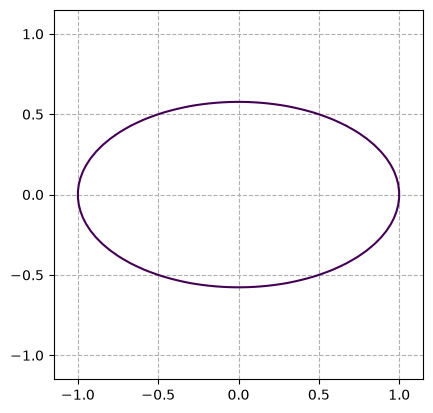

In [7]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-1.0, 1.0, 50)
y = np.linspace(-1.0, 1.0, 50)
X, Y = np.meshgrid(x,y)
F = (1)*(X**2) + (3)*(Y**2) - 1.0
fig, ax = plt.subplots()
ax.contour(X,Y,F,[0])
ax.set_aspect('equal')
plt.xlim(-1.15,1.15)
plt.ylim(-1.15,1.15)
plt.grid(linestyle='--')
plt.show()

* **Curva  elíptica simétrica:** Una elípse es una curva que consiste en un conjunto de puntos en un plano producida por la suma de las distancias f1 y f2 desde un par de puntos fijos y focales F1 y F2 hacia la curva. Donde F1 y F2 se encuentran a una distancia constante 2c. El eje mayor representa la distancia constante 2a y a es el eje semimayor. El eje menor representa la distancia 2b y b es el eje semimenor. Es decir, la elípse es una curva plana cerrada con doble eje de simetría.  
ref: https://mathworld.wolfram.com/Ellipse.html

C:\Users\berio\AppData\Local\Temp\ipykernel_2896\3933977957.py:4: RuntimeWarning: invalid value encountered in sqrt
  y = np.sqrt(-x**2 + 0.7)


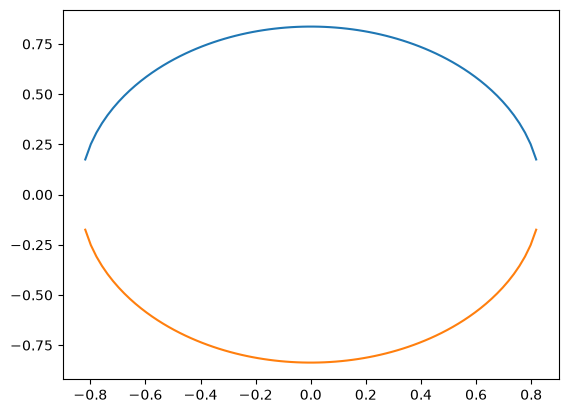

In [8]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-1, 1, 100)
y = np.sqrt(-x**2 + 0.7)
plt.plot(x, y)
plt.plot(x, -y)

* **Grupo Cíclico Extenso:** La elipse puede ofrecer un grupo multiplicativo alternativo a $Z_n^*$. Una curva elíptica es un tipo especial de ecuación polinomial en un campo finito $GF(p)$. En definitiva, una curva elíptica en $Z_p$ con $p>3$, es un conjunto de pares $(x,y)$ que pertenecen a $Z_p$, y cumplen $y^2= x^3+ax+b$ $(mod$ $p)$.

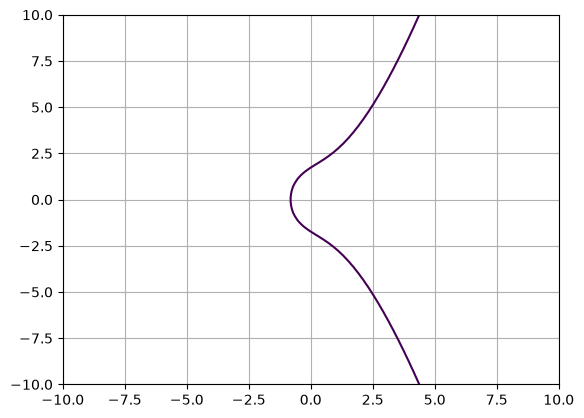

In [9]:
import matplotlib.pyplot as plt 
import numpy as np
y, x = np.ogrid[-10:10:100j, -10:10:100j]
a, b = 3, 3
plt.contour(x.ravel(), y.ravel(), pow(y, 2) - pow(x, 3) - x * a - b, [0])
plt.grid()
plt.show()

* **Elemento Neutro:** Para establecer un grupo finito es necesario un elemento neutro $O$, tal que $P+O=P$ y $P+(-P)=O$. Luego, el inverso del punto es $P = (x_p,-y_p)$, aquel punto reflejado a través del eje $x$.

In [10]:
import numpy as np
def invP(x,y,m):
    yy = (m - y) % m
    iP = np.array([x,yy])
    return iP
P = np.array([4,5])#np.array([8,10])
p = 31#29
print(invP(P[0],P[1],p))

[ 4 26]


* **Operación Adición Punto:** Dado un campo finito primo $GF(p)$, la adición y duplicación de puntos en la curva elíptica satisface $x_3 = s^2 - x_1 - x_2 (mod$ $p)$ ; $y_3 = s(x_1 - x_3) - y_1 (mod$ $p)$. Donde, sí $P \neq 0$, entonces $S = (y_2 - y_1)*(x_2 - x_1)^{(-1)}$.

In [11]:
import numpy as np
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
def poly():
    ec = [1,0,2,2] 
    return (ec[2])
def addP(P,Q,a,m):
    S = ((Q[1]-P[1]) * eea(Q[0]-P[0],m)[1]) % m
    x3 = (pow(S,2) - P[0] - Q[0]) % m
    y3 = (S*(P[0] - x3) - P[1]) % m
    return x3, y3
P = np.array([5,1])
Q = np.array([6,3])
m = 17
R =(addP(P,Q,poly(),m))
print(R)

(10, 6)


* **Operación Duplicación Punto:** Dado un campo finito primo $GF(p)$, la adición y duplicación de puntos en la curva elíptica satisface $x_3 = s^2 - x_1 - x_2 (mod$ $p)$ ; $y_3 = s(x_1 - x_3) - y_1 (mod$ $p)$. Donde, sí $P = 0$, entonces $S = (3x_1^2 +a)*(2y_1)^{(-1)}$

In [12]:
import numpy as np
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
def poly():
    ec = [1,0,2,2]
    return (ec[2])
def duP(P,a,m):
    S = ((3*(pow(P[0],2)) + a) * eea(2*P[1],m)[1] ) % m
    x3 = (pow(S,2) - 2*P[0]) % m
    y3 = (S*(P[0] - x3) - P[1]) % m
    return x3, y3
P = np.array([5,1])
m = 31#17
R = duP(P,poly(),m)
print(R)

(23, 19)


* **Cardinalidad:** Dada una curva elíptica $E$ modulo $p$, el número de puntos en la curva se denota como $\#E$ y se encuentra entre los límites $\#E > p+1-2sqrt(p)$ y $\#E < p+1+2sqrt(p)$.  
 _Código adaptado_
Ref: https://crypto.stackexchange.com/users/73222/

In [13]:
import math
p = 23
left = p + 1 - 2*(math.sqrt(p))
right = p + 1 + 2*(math.sqrt(p))
print(left, right)
campo = pow(2,p) - pow(2,11)
print(campo)

14.408336953374562 33.59166304662544
8386560


In [14]:
import numpy as np
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
def poly():
    ec = [1,5,12] 
    return (ec[1])
def oP(P,Q,a,m):
    for i in range(2,50):
        if (P[0] == Q[0] and P[1] == Q[1]):
         S=((3*(pow(P[0],2)) + a) * eea(2*P[1],m)[1] ) % m
        else:
         S=((Q[1]-P[1]) * eea(Q[0]-P[0],m)[1]) % m
        x3=(pow(S,2) - P[0] - Q[0]) % m
        y3=(S*(P[0] - x3) - P[1]) % m
        print(str(i) + "P:\t", (x3,y3))
        Q[0],Q[1]=x3, y3 
P = np.array([4,5])
Q = np.array([7,21])
m = 17#31#29#17
print("1P:\t", (P[0],P[1]))
oP(P,Q,poly(),m)

1P:	 (4, 5)
2P:	 (8, 2)
3P:	 (13, 6)
4P:	 (4, 12)
5P:	 (9, 12)
6P:	 (8, 3)
7P:	 (1, 2)
8P:	 (16, 5)
9P:	 (14, 12)
10P:	 (0, 8)
11P:	 (0, 3)
12P:	 (11, 10)
13P:	 (15, 9)
14P:	 (6, 2)
15P:	 (5, 5)
16P:	 (8, 12)
17P:	 (7, 11)
18P:	 (10, 0)
19P:	 (7, 6)
20P:	 (8, 5)
21P:	 (5, 12)
22P:	 (6, 15)
23P:	 (15, 8)
24P:	 (11, 7)
25P:	 (0, 1)
26P:	 (5, 9)
27P:	 (7, 0)
28P:	 (5, 8)
29P:	 (0, 7)
30P:	 (11, 14)
31P:	 (4, 12)
32P:	 (9, 12)
33P:	 (8, 3)
34P:	 (1, 2)
35P:	 (16, 5)
36P:	 (14, 12)
37P:	 (0, 8)
38P:	 (0, 3)
39P:	 (11, 10)
40P:	 (15, 9)
41P:	 (6, 2)
42P:	 (5, 5)
43P:	 (8, 12)
44P:	 (7, 11)
45P:	 (10, 0)
46P:	 (7, 6)
47P:	 (8, 5)
48P:	 (5, 12)
49P:	 (6, 15)


**Actividad 3:** La multiplicación punto es análoga a la exponenciación de grupos multiplicativos. El algoritmo de cuadrados-y-multiplicaciones (square-and-multiply) puede ser usado para calcular las operaciones de adición y duplicación de puntos, donde el cómputo del cuadrado se transforma en la operación duplicación y la multiplicación se torna en la adición de $P$. Si $P$ es un punto inicial y $T$ es un punto final, luego $dP = T$ y es el número de saltos en la curva elítpica. Proponga una solución programática que demuestre la multiplicación punto. Señale los supuestos escogidos considerando el siguiente pseudocódigo.

Algorithm:


---



```
FOR i = t − 1 DOWNTO 0
    T = T + T mod n 
        IF di = 1 
            T = T + P mod n 2
RETURN (T)
```

### Supuestos escogidos

1. **Curva y punto inicial:** se usa $y^2 \equiv x^3 + 2x + 2 \pmod{17}$ con $P = (5, 1)$.
   El parámetro $a = 2$ se pasa explícitamente (no con `poly()`, que en celdas anteriores
   fue redefinida). En esta curva $P$ genera un grupo cíclico de orden 19.
2. **Punto en el infinito:** se representa con `None`. Las funciones de suma y doblado
   manejan los casos especiales: $P + \mathcal{O} = P$, $P + (-P) = \mathcal{O}$ y
   el doblado de un punto con $y = 0$ (tangente vertical).
3. **Condición inicial:** el acumulador parte en $T = \mathcal{O}$ y el ciclo recorre
   todos los bits de $d$, del más significativo al menos significativo. Es equivalente
   a partir en $T = P$ saltando el primer bit, pero sin caso especial y válido para $d = 0$.
4. **Traducción del pseudocódigo:** `T = T + T` corresponde a `duP` (doblado) y
   `T = T + P` a `addP` (suma), ejecutada solo cuando $d_i = 1$.
5. **Aritmética modular:** el inverso se calcula con `pow(x, -1, n)` y los puntos son
   tuplas de enteros de Python, para soportar módulos de cualquier tamaño
   (numpy se desborda sobre 64 bits).
6. **Verificación:** se calcula $dP$ para $d = 1, \dots, 20$. Se obtiene $19P = \mathcal{O}$
   y $20P = P$, lo que confirma el orden 19 del grupo.

In [3]:
# escriba aquí su código y markdown
import numpy as np
import math

def addP(P, Q, a, m):
    if P is None: return Q
    if Q is None: return P
    if P[0] == Q[0]:
        if (P[1] + Q[1]) % m == 0:
            return None              # P + (-P) = infinito
        return duP(P, a, m)          # P + P es un doblado
    S = (Q[1] - P[1]) * pow(Q[0] - P[0], -1, m) % m
    x3 = (S*S - P[0] - Q[0]) % m
    return x3, (S*(P[0] - x3) - P[1]) % m

def duP(P, a, m):
    if P is None or P[1] == 0:
        return None                  # tangente vertical
    S = (3*P[0]**2 + a) * pow(2*P[1], -1, m) % m
    x3 = (S*S - 2*P[0]) % m
    return x3, (S*(P[0] - x3) - P[1]) % m

def multP(P, d, a, n):
    T = None                         # partir del infinito evita el caso especial del primer bit
    for bit in bin(d)[2:]:
        T = duP(T, a, n)
        if bit == '1':
            T = addP(T, P, a, n)
    return T

P = (5, 1)      # tupla de int de Python, no np.array
n = 17
d = 13
a = 2

T = multP(P, d, a, n)

print(f"Punto inicial P: {P}")
print(f"Saltos d: {d}, en binario: {bin(d)[2:]}")
print(f"{d}P = T: {T}")
print("\nDemostración de saltos dP = T:")
for i in range(1, 21):
    print(f"{i}P: {multP(P, i, a, n)}")

Punto inicial P: (5, 1)
Saltos d: 13, en binario: 1101
13P = T: (16, 4)

Demostración de saltos dP = T:
1P: (5, 1)
2P: (6, 3)
3P: (10, 6)
4P: (3, 1)
5P: (9, 16)
6P: (16, 13)
7P: (0, 6)
8P: (13, 7)
9P: (7, 6)
10P: (7, 11)
11P: (13, 10)
12P: (0, 11)
13P: (16, 4)
14P: (9, 1)
15P: (3, 16)
16P: (10, 11)
17P: (6, 14)
18P: (5, 16)
19P: None
20P: (5, 1)


In [4]:
import math
Alice= (3**41 % 43) # Alice
Bob= (3**4 % 43) # Bob
print(Bob**41 % 43) # Shared Secret Alice
print(Alice**4 % 43) # Shared Secret Bob
print(Alice)
print(Bob)
#print(math.log(41,11) % 43)
#print(math.log(3,72) % 43)
#print(3**72 % 43)
#print(41**72 % 43)
#print(41**11 % 43)
print(3**45 % 43)
print(3**164 % 43)

17
17
29
38
27
17


In [5]:
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
n=9797
e=131
x1 = 123
x2 = 4333
print(eea(131,9600))
print(x1**3371 % n)
#print(x2**131 % )
#print(6292^131 % 9600)
#print(1024^131 % 9600)
#print(4768^131 % 9600)
#print(1424^131 % 9600)

#print(math.gcd(7,96))

(1, np.int64(3371), np.int64(-46))
6292


In [6]:
import math
def eea(a,b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, s, t = eea(b % abs(a), abs(a))
        return (g, np.sign(a)*(t - (b // a) * s), s)
p = 59
q = 29
a = 3
d = 23 #7    
B = a**d % p
print(B)
Hx = 2 #26
Ke = 13 #13 #10
r= (a**Ke % p) % q
s= ((Hx + (d*r)) * eea(Ke,q)[1]) % q
print(r,s, eea(Ke,q)[1])
w = eea(s,q)[1] % q
u1= w*Hx % q
u2= w*r % q
print(w,u1,u2) 
v0 = (a**u1) % p
v1 = (B**u2) % p
v = (v0 * v1 % p) % q
print(r,v)


45
25 2 9
15 1 27
25 9


**Actividad 4:** Compare el desempeño de (dP) en dos modelos afines: Weierstrass y Montgomery, reusando el double-and-add de la Actividad 3. El objetivo no es “romper” la curva, sino medir por qué Montgomery suele ser más eficiente en multiplicación por escalar (aritmética (x)-only, escalera regular) frente a Weierstrass afín (inversiones en cada suma/doble).

- Weierstrass corta: $(y^2 = x^3 + ax + b)$
- Montgomery: $(By^2 = x^3 + Ax^2 + x)$

**Supuestos:**
- Se usan enteros nativos de Python (precisión arbitraria) y `pow(x, -1, p)` para el inverso modular. No se usa numpy, que se desborda sobre 64 bits.
- El punto en el infinito se representa con `None` en Weierstrass y con $Z = 0$ en Montgomery.
- Como la escalera trabaja solo con la coordenada $x$, la comparación entre modelos se hace sobre $x$: $P$ y $-P$ tienen la misma $x$ y la escalera no los distingue.
- Los tiempos absolutos dependen del equipo y del intérprete de Python; lo representativo es la razón entre ambos modelos.

In [20]:
import random
import time
import matplotlib.pyplot as plt

# Contador de operaciones de grupo, para comparar algoritmos sin depender del reloj
cuenta = {"add": 0, "dbl": 0, "inv": 0, "escalon": 0}

def reiniciar_cuenta():
    for k in cuenta:
        cuenta[k] = 0

## Weierstrass afín (double-and-add de la Actividad 3, con contadores)

In [21]:
def w_add(P, Q, a, p):
    if P is None:
        return Q
    if Q is None:
        return P
    if P[0] == Q[0]:
        if (P[1] + Q[1]) % p == 0:
            return None                      # P + (-P) = infinito
        return w_dbl(P, a, p)
    cuenta["add"] += 1
    cuenta["inv"] += 1
    s = (Q[1] - P[1]) * pow(Q[0] - P[0], -1, p) % p
    x3 = (s * s - P[0] - Q[0]) % p
    return x3, (s * (P[0] - x3) - P[1]) % p

def w_dbl(P, a, p):
    if P is None or P[1] == 0:
        return None                          # tangente vertical
    cuenta["dbl"] += 1
    cuenta["inv"] += 1
    s = (3 * P[0] * P[0] + a) * pow(2 * P[1], -1, p) % p
    x3 = (s * s - 2 * P[0]) % p
    return x3, (s * (P[0] - x3) - P[1]) % p

def w_mult(P, d, a, p):
    # double-and-add: recorre los bits de d del más al menos significativo
    T = None
    for bit in bin(d)[2:]:
        T = w_dbl(T, a, p)
        if bit == "1":
            T = w_add(T, P, a, p)
    return T

## Montgomery, escalera x-only

In [22]:
def x_dbl(X, Z, a24, p):
    t1 = (X + Z) ** 2 % p
    t2 = (X - Z) ** 2 % p
    t3 = t1 - t2                             # = 4XZ
    return t1 * t2 % p, t3 * (t2 + a24 * t3) % p

def x_add(XP, ZP, XQ, ZQ, x0, p):
    U = (XP - ZP) * (XQ + ZQ)
    V = (XP + ZP) * (XQ - ZQ)
    return (U + V) ** 2 % p, x0 * (U - V) ** 2 % p

def ladder(x, d, A, p):
    a24 = (A + 2) * pow(4, -1, p) % p
    R0, R1 = (1, 0), (x, 1)                  # R0 = infinito, R1 = P
    for bit in bin(d)[2:]:
        cuenta["escalon"] += 1
        if bit == "0":
            R1 = x_add(*R0, *R1, x, p)
            R0 = x_dbl(*R0, a24, p)
        else:
            R0 = x_add(*R0, *R1, x, p)
            R1 = x_dbl(*R1, a24, p)
    X0, Z0 = R0
    if Z0 % p == 0:
        return None                          # d múltiplo del orden de P
    cuenta["inv"] += 1
    return X0 * pow(Z0, -1, p) % p           # la única inversión

## Conversión Montgomery → Weierstrass

In [23]:
def mont_a_weier(A, B, p):
    a = (3 - A * A) * pow(3 * B * B, -1, p) % p
    b = (2 * A**3 - 9 * A) * pow(27 * B**3, -1, p) % p
    return a, b

def x_mont_a_weier(x, A, B, p):
    return (x * pow(B, -1, p) + A * pow(3 * B, -1, p)) % p

def punto_mont_a_weier(P, A, B, p):
    x, y = P
    return x_mont_a_weier(x, A, B, p), y * pow(B, -1, p) % p

def en_curva_weier(P, a, b, p):
    u, v = P
    return (v * v - (u**3 + a * u + b)) % p == 0

def comparar(P_mont, d, A, B, p):
    # True si ladder (Montgomery) y double-and-add (Weierstrass) dan el mismo dP
    a, _ = mont_a_weier(A, B, p)
    xm = ladder(P_mont[0], d, A, p)
    Tw = w_mult(punto_mont_a_weier(P_mont, A, B, p), d, a, p)
    if xm is None or Tw is None:
        return xm is None and Tw is None
    return x_mont_a_weier(xm, A, B, p) == Tw[0]

## Verificación en la curva pequeña

In [24]:
def es_cuadrado(v, p):
    v %= p
    return v == 0 or pow(v, (p - 1) // 2, p) == 1

def puntos_montgomery(p, A, B):
    iB = pow(B, -1, p)
    puntos = []
    for x in range(p):
        v = (x**3 + A * x * x + x) * iB % p
        if es_cuadrado(v, p):
            puntos += [(x, y) for y in range(p) if y * y % p == v]
    return puntos

p, A, B = 101, 3, 1
a, b = mont_a_weier(A, B, p)
P = (24, 27)
Pw = punto_mont_a_weier(P, A, B, p)

print("#E =", len(puntos_montgomery(p, A, B)) + 1)
print("Weierstrass equivalente: a =", a, ", b =", b)
print("P en Weierstrass:", Pw, "| en la curva:", en_curva_weier(Pw, a, b, p))
print("x(dP) con la escalera, d = 1..8:", [ladder(P[0], d, A, p) for d in range(1, 9)])
print("Coinciden para d = 1..30:", all(comparar(P, d, A, B, p) for d in range(1, 31)))
print("Weierstrass 5P y 5(-P):", w_mult(Pw, 5, a, p), w_mult((Pw[0], p - Pw[1]), 5, a, p))

#E = 96
Weierstrass equivalente: a = 99 , b = 1
P en Weierstrass: (25, 27) | en la curva: True
x(dP) con la escalera, d = 1..8: [24, 97, 14, 54, 84, 100, 95, 58]
Coinciden para d = 1..30: True
Weierstrass 5P y 5(-P): (85, 49) (85, 52)


## Verificación con Curve25519

In [25]:
def raiz_mod_5_8(v, p):
    # raíz cuadrada modular para p ≡ 5 (mod 8)
    r = pow(v, (p + 3) // 8, p)
    if r * r % p == v % p:
        return r
    r = r * pow(2, (p - 1) // 4, p) % p
    assert r * r % p == v % p, "v no es un cuadrado"
    return r

p = 2**255 - 19
A, B = 486662, 1
ell = 2**252 + 27742317777372353535851937790883648493
a, b = mont_a_weier(A, B, p)

x9 = 9
P = (x9, raiz_mod_5_8(x9**3 + A * x9 * x9 + x9, p))
Pw = punto_mont_a_weier(P, A, B, p)

print("P en Weierstrass equivalente:", en_curva_weier(Pw, a, b, p))
print("ℓ·P = infinito (escalera):", ladder(x9, ell, A, p) is None)
print("ℓ·P = infinito (Weierstrass):", w_mult(Pw, ell, a, p) is None)

random.seed(252)
print("Coinciden en 20 escalares aleatorios de 255 bits:",
      all(comparar(P, random.getrandbits(255), A, B, p) for _ in range(20)))

P en Weierstrass equivalente: True
ℓ·P = infinito (escalera): True
ℓ·P = infinito (Weierstrass): True
Coinciden en 20 escalares aleatorios de 255 bits: True


## Cuánto cuesta una inversión

In [26]:
def medir(f, n=20000):
    t = time.perf_counter()
    for _ in range(n):
        f()
    return (time.perf_counter() - t) / n

x, y = random.getrandbits(255) % p, random.getrandbits(255) % p
t_vacio = medir(lambda: None)                 # costo de la llamada, se descuenta
t_mul = medir(lambda: x * y % p) - t_vacio
t_inv = medir(lambda: pow(x, -1, p)) - t_vacio

print(f"Multiplicación modular: {t_mul * 1e9:7.1f} ns")
print(f"Inversión modular:      {t_inv * 1e9:7.1f} ns")
print(f"Una inversión ≈ {t_inv / t_mul:.0f} multiplicaciones")

Multiplicación modular:   289.0 ns
Inversión modular:      14038.5 ns
Una inversión ≈ 49 multiplicaciones


## Medición según tamaño del escalar

In [27]:
def escalar_de(bits):
    return random.getrandbits(bits) | (1 << (bits - 1))   # fuerza exactamente 'bits' bits

def medir_algoritmo(f, escalares):
    reiniciar_cuenta()
    t = time.perf_counter()
    for d in escalares:
        f(d)
    t = (time.perf_counter() - t) / len(escalares)
    return t, {k: v / len(escalares) for k, v in cuenta.items()}

tamanos = [16, 32, 64, 128, 192, 255]
REPS = 40
filas = []
for bits in tamanos:
    escalares = [escalar_de(bits) for _ in range(REPS)]
    tw, cw = medir_algoritmo(lambda d: w_mult(Pw, d, a, p), escalares)
    tm, cm = medir_algoritmo(lambda d: ladder(x9, d, A, p), escalares)
    filas.append((bits, tw, tm, cw, cm))

print(f"{'bits':>4} | {'Weierstrass':>11} | {'Montgomery':>10} | {'razón':>5} | "
      f"{'dbl':>5} {'add':>5} {'inv W':>6} | {'pasos':>5} {'inv M':>5}")
print("-" * 78)
for bits, tw, tm, cw, cm in filas:
    print(f"{bits:>4} | {tw * 1e3:>8.3f} ms | {tm * 1e3:>7.3f} ms | {tw / tm:>4.1f}x | "
          f"{cw['dbl']:>5.0f} {cw['add']:>5.1f} {cw['inv']:>6.1f} | {cm['escalon']:>5.0f} {cm['inv']:>5.0f}")

bits | Weierstrass | Montgomery | razón |   dbl   add  inv W | pasos inv M
------------------------------------------------------------------------------
  16 |    0.365 ms |   0.071 ms |  5.1x |    15   6.9   21.9 |    16     1
  32 |    0.831 ms |   0.129 ms |  6.4x |    31  14.9   45.9 |    32     1
  64 |    1.474 ms |   0.246 ms |  6.0x |    63  31.5   94.5 |    64     1
 128 |    3.300 ms |   0.475 ms |  7.0x |   127  64.8  191.8 |   128     1
 192 |    5.054 ms |   0.710 ms |  7.1x |   191  94.6  285.6 |   192     1
 255 |    6.642 ms |   0.945 ms |  7.0x |   254 123.9  377.9 |   255     1


# Gráficos

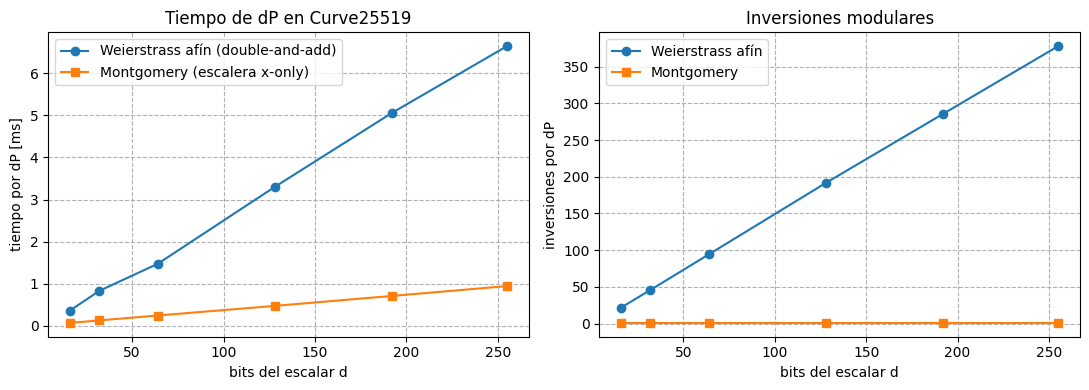

In [28]:
bits = [f[0] for f in filas]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(bits, [f[1] * 1e3 for f in filas], "o-", label="Weierstrass afín (double-and-add)")
ax1.plot(bits, [f[2] * 1e3 for f in filas], "s-", label="Montgomery (escalera x-only)")
ax1.set_xlabel("bits del escalar d")
ax1.set_ylabel("tiempo por dP [ms]")
ax1.set_title("Tiempo de dP en Curve25519")
ax1.grid(linestyle="--")
ax1.legend()

ax2.plot(bits, [f[3]["inv"] for f in filas], "o-", label="Weierstrass afín")
ax2.plot(bits, [f[4]["inv"] for f in filas], "s-", label="Montgomery")
ax2.set_xlabel("bits del escalar d")
ax2.set_ylabel("inversiones por dP")
ax2.set_title("Inversiones modulares")
ax2.grid(linestyle="--")
ax2.legend()

plt.tight_layout()
plt.show()

## Regularidad

In [29]:
d_liviano = 1 << 254             # 100...0
d_pesado = (1 << 255) - 1        # 111...1

for nombre, d in [("peso 1  ", d_liviano), ("peso 255", d_pesado)]:
    tw, cw = medir_algoritmo(lambda d: w_mult(Pw, d, a, p), [d] * 30)
    tm, cm = medir_algoritmo(lambda d: ladder(x9, d, A, p), [d] * 30)
    print(f"{nombre} | Weierstrass: {tw * 1e3:6.3f} ms, {cw['dbl']:.0f} dbl + {cw['add']:.0f} add"
          f" | Montgomery: {tm * 1e3:6.3f} ms, {cm['escalon']:.0f} pasos")

peso 1   | Weierstrass:  4.016 ms, 254 dbl + 0 add | Montgomery:  0.939 ms, 255 pasos
peso 255 | Weierstrass:  8.467 ms, 254 dbl + 254 add | Montgomery:  0.945 ms, 255 pasos


### Conclusiones

**Correctitud.** Ambos modelos calculan el mismo $dP$: coinciden para todo $d$ entre 1 y 30 en la curva pequeña y para 20 escalares aleatorios de 255 bits en Curve25519. Además, ambos entregan el punto en el infinito para $\ell P$, donde $\ell$ es el orden del punto base. Esto confirma que la curva Montgomery y su Weierstrass equivalente representan el mismo grupo.

**Eficiencia.** En Curve25519, la escalera de Montgomery fue **≈ 5 veces** más rápida que el double-and-add afín para escalares de 255 bits. La diferencia se explica principalmente por las inversiones modulares

Según la medición, una inversión modular cuesta ≈ 39 multiplicaciones con números de 255 bits. Por lo tanto, Weierstrass afín paga el equivalente a varias decenas de multiplicaciones por bit, mientras que Montgomery paga ≈ 10. Además, la escalera nunca calcula la coordenada $y$, lo que ahorra operaciones en cada paso.

En ambos modelos el tiempo crece linealmente con el número de bits de $d$, porque los dos procesan un bit por iteración. La diferencia está en la pendiente: cada bit es mucho más caro en Weierstrass afín.

### Fin de la Tarea!!!